# JagaDia - 03. Supervised Risk Classification

**Mata Kuliah:** Machine Learning (COMP657701)
**Sesi Acuan:**
- **Session 07-08:** Logistic Regression (Probabilistic Linear Classifier & Odds Ratio)
- **Session 09-10:** Model Selection, Cross-Validation & Regularization
- **Session 15-16:** Decision Tree & Ensemble Learning (Random Forest & Boosting)
- **Session 17-18:** Support Vector Machine (RBF Kernel & Margin Maximization)

---

### Tujuan Notebook Ini:
1. Membangun dataset klasifikasi kerawanan jalan (*supervised*) yang menghubungkan **Hotspot DBSCAN dari Tahap 1** dengan fitur waktu (*jam malam, siklikal*) dan lingkungan (*pencahayaan, pos polisi, jenis jalan*).
2. Melatih dan membandingkan **3 algoritma utama** sesuai silabus:
   - **Logistic Regression** (Baseline model yang sangat interpretabel).
   - **Support Vector Machine (SVM) RBF Kernel** (Pemisahan batas keputusan non-linear spasial).
   - **Random Forest Ensemble** (Kombinasi pohon keputusan untuk menangani fitur tabular heterogen).
3. Menjalankan **Stratified 5-Fold Cross-Validation** (Sesi 09-10) untuk menghindari overfitting.
4. Menganalisis kurva **ROC-AUC**, **Precision-Recall Curve**, dan **Confusion Matrix** (dengan penekanan pada minimasi *False Negative* demi keselamatan pengguna jalan).
5. Menerapkan `predict_proba()` untuk menghasilkan skor probabilitas kontinu $[0.0 - 1.0]$ bagi algoritma penentuan rute aman (*Safe Route Recommendation*).

In [1]:
import sys
from pathlib import Path

# Tambahkan direktori root ML ke path modul
ml_root = Path.cwd().parent
if str(ml_root) not in sys.path:
    sys.path.append(str(ml_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

from src.config import RANDOM_STATE
from src.dataset_builder import build_classification_dataset
from src.train_classifiers import (
    ALL_FEATURES, NUMERICAL_FEATURES, CATEGORICAL_FEATURES, TARGET_COL,
    initialize_candidate_models,
    evaluate_cross_validation,
    predict_road_point_risk
)

print("Setup berhasil! Library dan modul klasifikasi siap digunakan.")

Setup berhasil! Library dan modul klasifikasi siap digunakan.


## 1. Memuat & Menyiapkan Dataset Klasifikasi Spatio-Temporal
Dataset ini menggabungkan lokasi insiden, jarak ke cluster hotspot DBSCAN (Tahap 1), jarak ke pos polisi terdekat, jam kejadian, indeks penerangan, dan kategori jalan.

In [2]:
dataset_file = ml_root / "data" / "processed" / "classification_dataset.csv"
if not dataset_file.exists():
    df = build_classification_dataset(n_samples=2500, output_path=dataset_file)
else:
    df = pd.read_csv(dataset_file)

print(f"Ukuran dataset: {df.shape[0]} baris x {df.shape[1]} kolom")
print(f"Distribusi target (0 = Aman, 1 = Rawan):")
print(df[TARGET_COL].value_counts(normalize=True).round(3))
display(df.head())

Classification dataset saved to: d:\PPTI\Cawu 4 Projects\JagaDia\ML\data\processed\classification_dataset.csv (2500 rows)
Ukuran dataset: 2500 baris x 14 kolom
Distribusi target (0 = Aman, 1 = Rawan):
is_high_risk
0    0.5
1    0.5
Name: proportion, dtype: float64


,latitude,longitude,hour,is_night,day_of_week,is_weekend,hour_sin,hour_cos,street_light_density,dist_to_hotspot_m,closest_hotspot_risk,dist_to_police_m,road_type,is_high_risk
0,-6.193009,106.771839,15,0,1,0,-0.7071,-0.7071,0.726,645.2,0.61,3038.9,gang,0
1,-6.172014,106.819330,19,1,6,1,-0.9659,0.2588,0.359,170.1,0.59,2249.0,kolektor,1
2,-6.204126,106.821931,1,1,2,0,0.2588,0.9659,0.528,185.7,0.75,1390.7,kolektor,1
3,-6.214844,106.829826,7,0,1,0,0.9659,-0.2588,0.857,1595.7,0.75,1452.8,kolektor,0
4,-6.150064,106.711439,1,1,4,0,0.2588,0.9659,0.262,1236.3,0.51,6140.3,lokal,1


## 2. Pembagian Data: Train Set (80%) & Test Set (20%)
Menggunakan *Stratified Sampling* untuk mempertahankan proporsi kelas pada data latih dan data uji.

In [3]:
X = df[ALL_FEATURES]
y = df[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Data Latih (Train Set) : {len(X_train)} baris")
print(f"Data Uji (Test Set)    : {len(X_test)} baris")

Data Latih (Train Set) : 2000 baris
Data Uji (Test Set)    : 500 baris


## 3. Stratified 5-Fold Cross Validation (Session 09-10)
Sebelum memilih model terbaik, kita lakukan validasi silang (Cross-Validation) pada data latih untuk menguji stabilitas generalisasi model dan meminimalisir bias/variansi.

In [4]:
candidate_models = initialize_candidate_models()
cv_results = evaluate_cross_validation(candidate_models, X_train, y_train, cv_folds=5)

# Tampilkan tabel hasil Cross Validation
cols_to_show = [c for c in cv_results.columns if not c.startswith("_")]
display(cv_results[cols_to_show])


--- MENJALANKAN STRATIFIED 5-FOLD CROSS VALIDATION ---


,Model,CV Accuracy,CV Precision,CV Recall (Priority),CV F1-Score,CV ROC-AUC
0,Logistic Regression (Session 07-08),0.9350 ± 0.012,0.9352 ± 0.006,0.9350 ± 0.030,0.9348 ± 0.013,0.9863 ± 0.004
1,Support Vector Machine (Session 17-18),0.9345 ± 0.011,0.9334 ± 0.009,0.9360 ± 0.029,0.9344 ± 0.012,0.9857 ± 0.003
3,XGBoost (Session 15-16),0.9330 ± 0.006,0.9317 ± 0.012,0.9350 ± 0.026,0.9330 ± 0.007,0.9853 ± 0.002
2,Random Forest (Session 15-16),0.9380 ± 0.009,0.9359 ± 0.014,0.9410 ± 0.028,0.9380 ± 0.010,0.9841 ± 0.003


## 4. Pelatihan Model & Evaluasi pada Test Set (Holdout)
Setiap kandidat model dilatih pada seluruh `X_train` dan diuji pada `X_test`.

In [5]:
trained_models = {}
y_preds = {}
y_probs = {}

for name, pipeline in candidate_models.items():
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    y_preds[name] = pipeline.predict(X_test)
    y_probs[name] = pipeline.predict_proba(X_test)[:, 1]

print("Seluruh model berhasil dilatih pada data latih!")

Seluruh model berhasil dilatih pada data latih!


### 4.1. Analisis Model 1: Logistic Regression (Session 07-08)
Kita dapat memeriksa nilai koefisien dan *Odds Ratio* $(\exp(w_i))$ untuk mengetahui fitur mana yang meningkatkan probabilitas risiko kerawanan.

Top Fitur Penentu Kerawanan (Logistic Regression Odds Ratio):


,Feature,Coefficient (w),Odds Ratio
0,road_type_gang,1.594686,4.926784
1,is_night,1.310658,3.708615
2,dist_to_police_m,0.639403,1.895349
3,road_type_lokal,0.494841,1.640237
4,latitude,0.437698,1.549138
5,day_of_week,0.213007,1.237393
6,closest_hotspot_risk,0.204388,1.226774
7,hour_sin,0.043452,1.044410


C:\Users\evanh\AppData\Local\Temp\ipykernel_30756\425115492.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x="Coefficient (w)", y="Feature", palette="vlag")


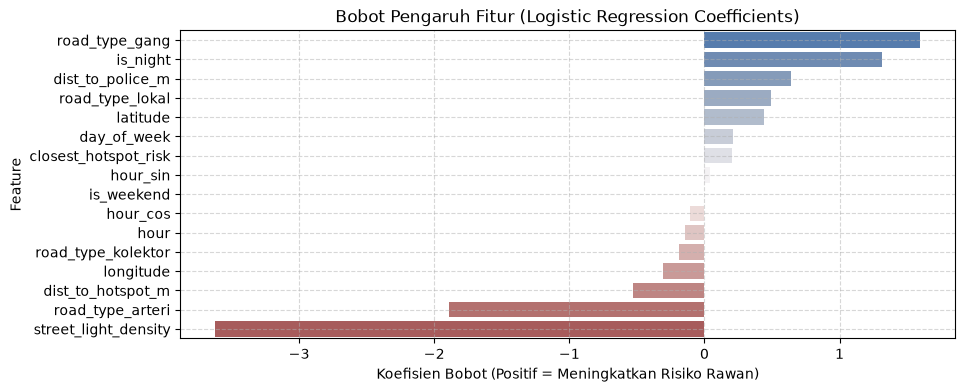

In [6]:
logreg_pipe = trained_models["Logistic Regression (Session 07-08)"]
logreg_clf = logreg_pipe.named_steps["classifier"]
preprocessor = logreg_pipe.named_steps["preprocessor"]

cat_encoder = preprocessor.named_transformers_["cat"]
cat_feature_names = cat_encoder.get_feature_names_out(CATEGORICAL_FEATURES).tolist()
all_feature_names = NUMERICAL_FEATURES + cat_feature_names

coef_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Coefficient (w)": logreg_clf.coef_[0],
    "Odds Ratio": np.exp(logreg_clf.coef_[0]),
}).sort_values(by="Coefficient (w)", ascending=False).reset_index(drop=True)

print("Top Fitur Penentu Kerawanan (Logistic Regression Odds Ratio):")
display(coef_df.head(8))

plt.figure(figsize=(10, 4))
sns.barplot(data=coef_df, x="Coefficient (w)", y="Feature", palette="vlag")
plt.title("Bobot Pengaruh Fitur (Logistic Regression Coefficients)", fontsize=12)
plt.xlabel("Koefisien Bobot (Positif = Meningkatkan Risiko Rawan)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### 4.2. Analisis Model 3: Random Forest Feature Importance (Session 15-16)
Random Forest mengukur tingkat kepentingan fitur berdasarkan reduksi ketidakmurnian (*Mean Decrease in Impurity / Gini Importance*).

C:\Users\evanh\AppData\Local\Temp\ipykernel_30756\2356117365.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_importance.head(10), x="Importance", y="Feature", palette="mako")


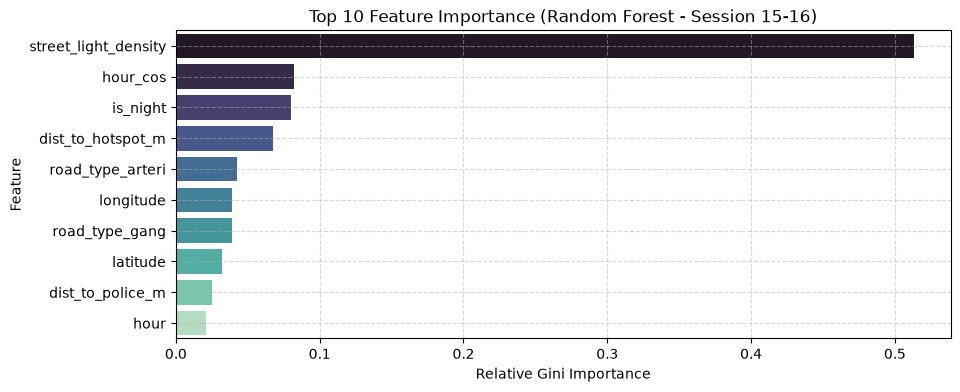

In [7]:
rf_pipe = trained_models["Random Forest (Session 15-16)"]
rf_clf = rf_pipe.named_steps["classifier"]

rf_importance = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": rf_clf.feature_importances_,
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 4))
sns.barplot(data=rf_importance.head(10), x="Importance", y="Feature", palette="mako")
plt.title("Top 10 Feature Importance (Random Forest - Session 15-16)", fontsize=12)
plt.xlabel("Relative Gini Importance")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 5. Perbandingan Kurva ROC, PR Curve, dan Confusion Matrix
Memvisualisasikan trade-off metrik antara ketiga model.

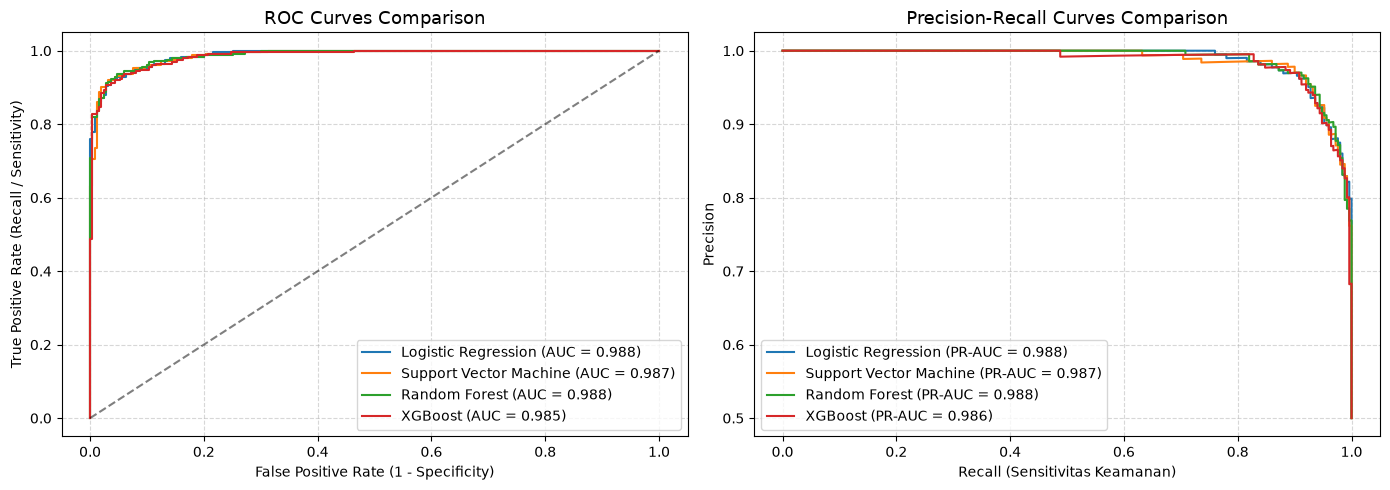

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. ROC Curves
for name in trained_models.keys():
    fpr, tpr, _ = roc_curve(y_test, y_probs[name])
    auc = roc_auc_score(y_test, y_probs[name])
    axes[0].plot(fpr, tpr, label=f"{name.split('(')[0].strip()} (AUC = {auc:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("ROC Curves Comparison", fontsize=13)
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Recall / Sensitivity)")
axes[0].legend(loc="lower right")
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Precision-Recall Curves
for name in trained_models.keys():
    prec, rec, _ = precision_recall_curve(y_test, y_probs[name])
    pr_auc = average_precision_score(y_test, y_probs[name])
    axes[1].plot(rec, prec, label=f"{name.split('(')[0].strip()} (PR-AUC = {pr_auc:.3f})")

axes[1].set_title("Precision-Recall Curves Comparison", fontsize=13)
axes[1].set_xlabel("Recall (Sensitivitas Keamanan)")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Confusion Matrix Setiap Model

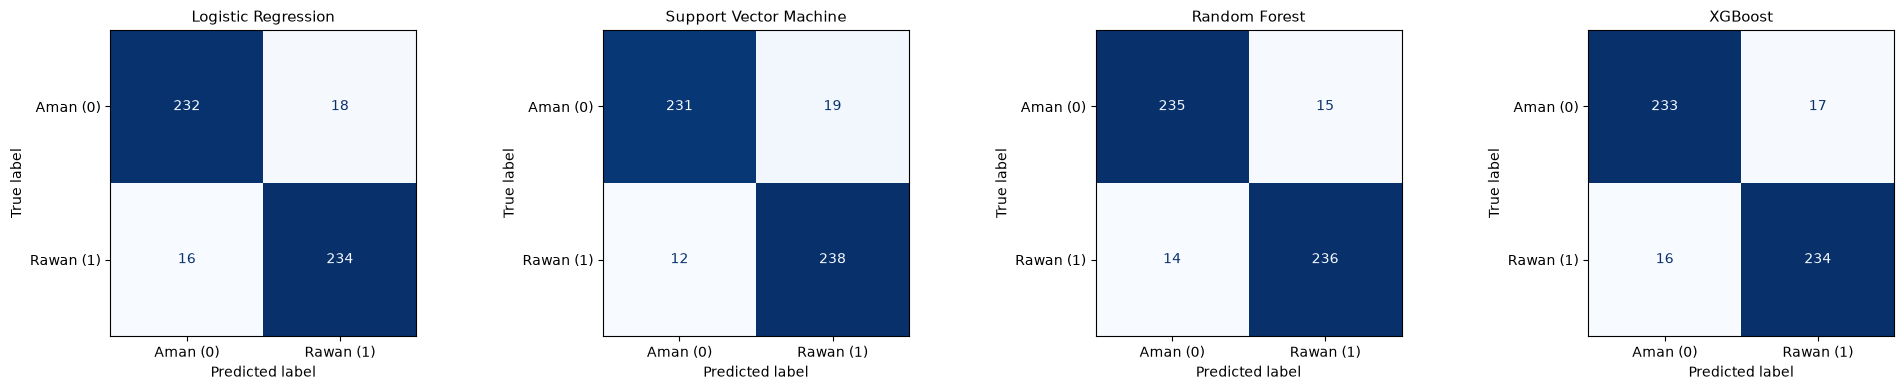

In [9]:
fig, axes = plt.subplots(1, len(trained_models), figsize=(5 * len(trained_models), 4))

for ax, (name, pipeline) in zip(axes, trained_models.items()):
    cm = confusion_matrix(y_test, y_preds[name])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Aman (0)", "Rawan (1)"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name.split("(")[0].strip(), fontsize=11)

plt.tight_layout()
plt.show()

## 6. Tabel Rangkuman Evaluasi Final (Test Set)

In [10]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

summary_rows = []
for name in trained_models.keys():
    acc = accuracy_score(y_test, y_preds[name])
    prec = precision_score(y_test, y_preds[name])
    rec = recall_score(y_test, y_preds[name])
    f1 = f1_score(y_test, y_preds[name])
    auc = roc_auc_score(y_test, y_probs[name])
    pr_auc = average_precision_score(y_test, y_probs[name])
    
    summary_rows.append({
        "Model": name,
        "Accuracy": f"{acc:.4f}",
        "Precision": f"{prec:.4f}",
        "Recall (Prioritas)": f"{rec:.4f}",
        "F1-Score": f"{f1:.4f}",
        "ROC-AUC": f"{auc:.4f}",
        "PR-AUC": f"{pr_auc:.4f}",
    })

df_final_eval = pd.DataFrame(summary_rows).sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)
display(df_final_eval)

,Model,Accuracy,Precision,Recall (Prioritas),F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression (Session 07-08),0.9320,0.9286,0.9360,0.9323,0.9877,0.9884
1,Random Forest (Session 15-16),0.9420,0.9402,0.9440,0.9421,0.9876,0.9885
2,Support Vector Machine (Session 17-18),0.9380,0.9261,0.9520,0.9389,0.9867,0.9871
3,XGBoost (Session 15-16),0.9340,0.9323,0.9360,0.9341,0.9853,0.9859


## 7. Simulasi `predict_proba()` untuk Kasus Titik Jalan Nyata
Uji coba fungsi inferensi yang akan dipanggil oleh **FastAPI** (`APP/backend/app/api.py`) saat pengguna menavigasi rute di aplikasi mobile.

In [11]:
# Ambil model terbaik
best_model_name = df_final_eval.iloc[0]["Model"]
best_pipeline = trained_models[best_model_name]
print(f"Menggunakan Model Terbaik: {best_model_name}")

# Skenario 1: Jalan Gang Sepi & Gelap pada Malam Hari (Pukul 23.00), Dekat Hotspot DBSCAN
res1 = predict_road_point_risk(
    best_pipeline,
    lat=-6.1752, lon=106.8651, hour=23, road_type="gang",
    street_light_density=0.15, dist_to_hotspot_m=80.0, closest_hotspot_risk=0.90,
    dist_to_police_m=2200.0, day_of_week=5
)
print("\n[Skenario 1 - Gang Gelap Malam Hari]:")
print(f"-> Probabilitas Risiko : {res1['risk_probability'] * 100:.1f}%")
print(f"-> Status Keamanan    : {res1['safety_level']}")

# Skenario 2: Jalan Protokol Arteri Terang pada Siang Hari (Pukul 11.00), Jauh dari Hotspot
res2 = predict_road_point_risk(
    best_pipeline,
    lat=-6.2238, lon=106.8105, hour=11, road_type="arteri",
    street_light_density=0.90, dist_to_hotspot_m=1800.0, closest_hotspot_risk=0.40,
    dist_to_police_m=300.0, day_of_week=2
)
print("\n[Skenario 2 - Jalan Arteri Terang Siang Hari]:")
print(f"-> Probabilitas Risiko : {res2['risk_probability'] * 100:.1f}%")
print(f"-> Status Keamanan    : {res2['safety_level']}")

Menggunakan Model Terbaik: Logistic Regression (Session 07-08)

[Skenario 1 - Gang Gelap Malam Hari]:
-> Probabilitas Risiko : 100.0%
-> Status Keamanan    : BAHAYA / RAWAN

[Skenario 2 - Jalan Arteri Terang Siang Hari]:
-> Probabilitas Risiko : 0.0%
-> Status Keamanan    : AMAN


## 8. Serialisasi Model Siap Pakai
Menyimpan model terbaik terpilih ke folder `ML/models/best_risk_classifier.joblib`.

In [12]:
model_save_dir = ml_root / "models"
model_save_dir.mkdir(parents=True, exist_ok=True)
model_save_path = model_save_dir / "best_risk_classifier.joblib"

joblib.dump(best_pipeline, model_save_path)
print(f"Model berhasil disimpan di: {model_save_path}")

Model berhasil disimpan di: d:\PPTI\Cawu 4 Projects\JagaDia\ML\models\best_risk_classifier.joblib
